#  <span style="color:#C133FF"> Loading niftis after optimization - Creating figures </span> 


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import nibabel as nib
from pathlib import Path

In [2]:
import os, sys, importlib
parent_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(parent_dir)
print(parent_dir)

c:\Users\Admin\Documents\msc_project\Image-processing-strategies


In [3]:
import monkey_tools.extract_metric
importlib.reload(monkey_tools.extract_metric)

from monkey_tools.extract_metric import cnr_wm_gm # re-import updated function

In [4]:
# Loading the simulated related data

initial_field_Hz_data = nib.load(r"R:\soothsayer\msc_data\chi_fitting\rosenberg_results\db0_035\mb_r1_solver_n_pad_constant_cropped\initial_field_demod_Hz.nii.gz").get_fdata()
fitted_dmod_field_Hz_data = nib.load(r"R:\soothsayer\msc_data\chi_fitting\rosenberg_results\db0_035\mb_r1_solver_n_pad_constant_cropped\fitted_field_demod_Hz.nii.gz").get_fdata()
vert_levels_data = nib.load(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_035\sim\for_rosenberg\cord_levels_crop.nii.gz").get_fdata()


In [5]:
# Loading the in-vivo related measured data - this should be already from 2 to 14
in_vivo_dmod_exp_field_Hz_df = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_035\chi_035_for_rosenberg\sub-2_OLD_Aspire_DEMOD_EXP_mean_per_level_1_15.csv")
in_vivo_dmod_inspp_field_Hz_df = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_035\chi_035_for_rosenberg\sub-2_OLD_Aspire_DEMOD_INSP_mean_per_level_1_15.csv")


In [6]:
in_vivo_dmod_exp_field_Hz_df

,dmod_B0_Hz
0,-46.142896
1,-79.613288
2,-91.700261
3,-83.964186
4,-51.015031
5,2.172705
6,63.506209
7,60.844696
8,50.249700
9,55.320273


In [7]:
in_vivo_dmod_inspp_field_Hz_df

,dmod_B0_Hz
0,-54.894076
1,-75.633244
2,-84.524619
3,-68.774478
4,-24.643149
5,42.451006
6,98.899320
7,80.806424
8,44.513886
9,32.401298


In [8]:
demod_avg_respiration = (in_vivo_dmod_exp_field_Hz_df+ in_vivo_dmod_inspp_field_Hz_df )/2
demod_avg_respiration

,dmod_B0_Hz
0,-50.518486
1,-77.623266
2,-88.112440
3,-76.369332
4,-37.829090
5,22.311856
6,81.202764
7,70.825560
8,47.381793
9,43.860785


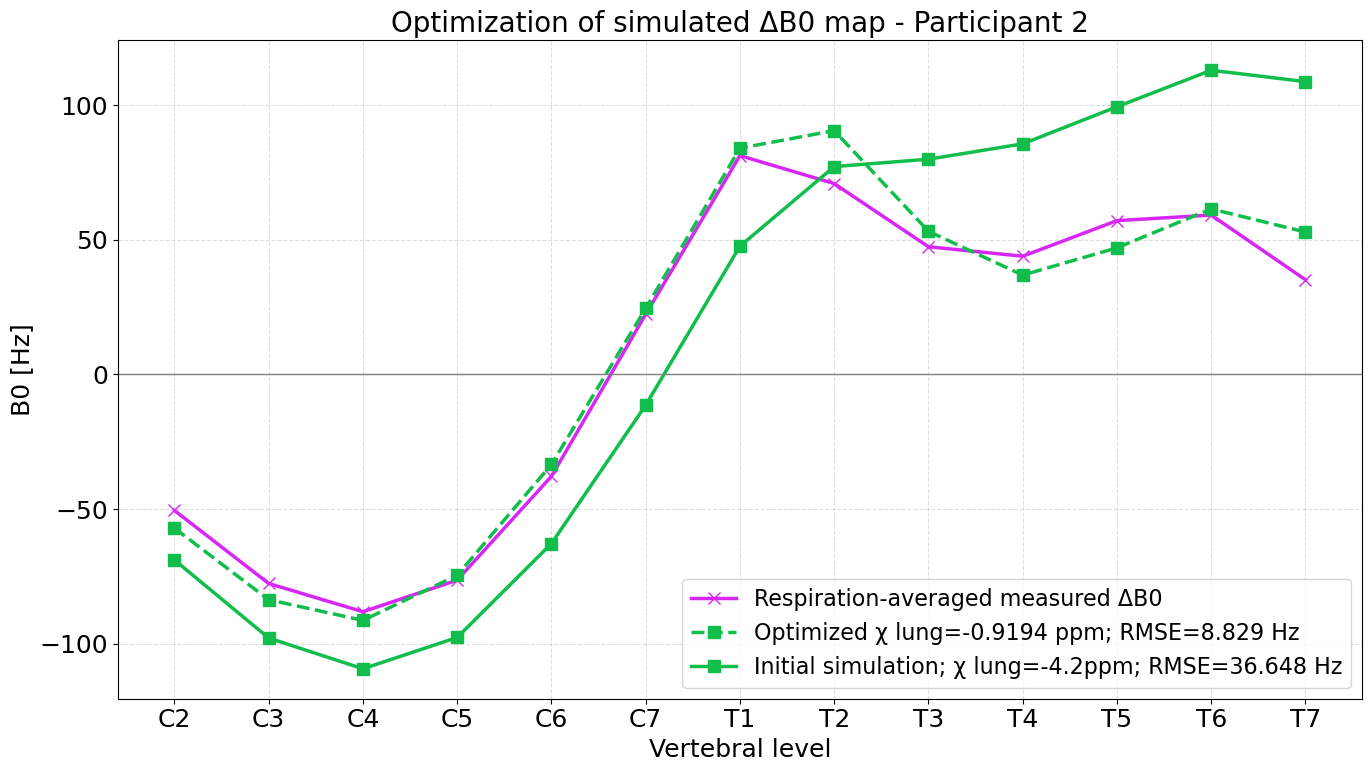

In [16]:

# Recreate average_lung_fit.png from saved optimization results
# No optimization or fieldmap simulation required!

results_dir = Path(
    r"R:\soothsayer\msc_data\chi_fitting\rosenberg_results\db0_035\mb_r1_solver_n_pad_constant_cropped"
)

fit_df = pd.read_csv(results_dir / "average_lung_fit.csv")

# Load profiles directly from CSV
levels = fit_df["VertebralLevel"]
measured = fit_df["MeasuredProfile_Hz"].to_numpy()
fitted = fit_df["FittedProfile_Hz"].to_numpy()

# Fitted parameters
chi = fit_df["FittedLungChi_ppm"].iloc[0]
rmse = fit_df["FitRMSE_Hz"].iloc[0]

# Initial simulation comparison
initial = fit_df["InitialProfile_Hz"].to_numpy()
initial_rmse = np.sqrt(np.mean((initial - measured)**2))

# --------------------------------------------------
# EDIT FIGURE LABELS HERE
# --------------------------------------------------
title = "Optimization of simulated ΔB0 map - Participant 2"
xlabel = "Vertebral level"
ylabel = "B0 [Hz]"

measured_label = "Respiration-averaged measured ΔB0"
fitted_label = f"Optimized χ lung={chi:.4f} ppm; RMSE={rmse:.3f} Hz"
initial_label = f"Initial simulation; χ lung=-4.2ppm; RMSE={initial_rmse:.3f} Hz"

# --------------------------------------------------
# PLOT
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 8))

ax.plot(levels, measured, "x-", color="#D627F5",
        label=measured_label)

ax.plot(levels, fitted, "s--", color="#11BD4B",
        label=fitted_label)

ax.plot(levels, initial, "s-", color="#11BD4B",
        label=initial_label)

ax.axhline(0, color="gray", linewidth=1)

ax.set(
    xlabel=xlabel,
    ylabel=ylabel,
    title=title
)

ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()

fig.tight_layout()

# Save as a NEW file to preserve the original
fig.savefig(
    results_dir / "average_lung_fit_replot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.rcParams.update({
    "font.size": 16,        # Default font size
    "axes.titlesize": 20,   # Plot title
    "axes.labelsize": 18,   # X and Y axis labels
    "xtick.labelsize": 18,  # X-axis ticks
    "ytick.labelsize": 18,  # Y-axis ticks
    "legend.fontsize": 16,  # Legend
})

plt.rcParams.update({
    "lines.linewidth": 2.5,
    "lines.markersize": 9,
})

plt.show()
